## Setup

In [2]:
# pandas: the DataFrame library, used to load and reshape the data
import pandas as pd

# matplotlib: the base plotting library, which everything else builds on
import matplotlib.pyplot as plt

# numpy: numerical arrays and math, used by some of the plots
import numpy as np

# seaborn: statistical plots on top of matplotlib (box, violin, heatmap, pairplot, ...)
import seaborn as sns

# plotly express: interactive charts you can hover over and zoom into
import plotly.express as px

# ydata_profiling: generates an automatic EDA report in one call
from ydata_profiling import ProfileReport

# Give all plots seaborn's cleaner default look
sns.set_theme()

# Read the cleaned CSV into a DataFrame (the path is relative to this notebook's folder)
df = pd.read_csv("../cleaned/dataminers_cleaner.csv")

/opt/homebrew/Caskroom/miniforge/base/envs/damml2026/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/d5/404vrwts7sxgmfr3p429j71w0000gn/T/ipykernel_23678/1483244111.py:17: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## 1. Bar chart of the motivations

**Question:** what share of all students ticked each of the four motivations?
Show one bar per motivation, with clear axis labels and a title.

Text(0, 0.5, 'Share of students')

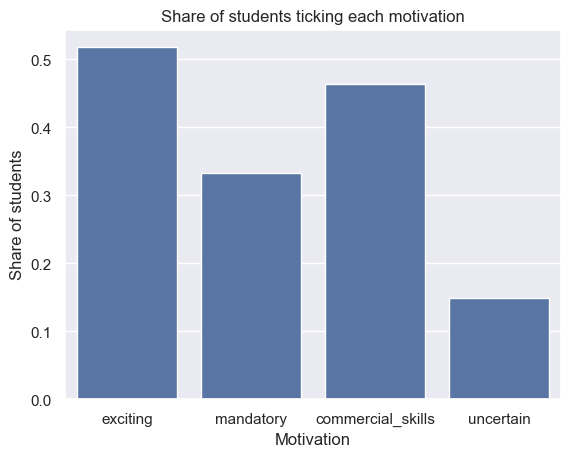

In [3]:
# The four 0/1 motivation columns, as a list of names
motivations = ["exciting", "mandatory", "commercial_skills", "uncertain"]

# Share of students who ticked each motivation (the mean of a 0/1 column is the share)
shares = df[motivations].mean()

# One bar per motivation
sns.barplot(shares)

# Title and axis labels
plt.title("Share of students ticking each motivation")
plt.xlabel("Motivation")
plt.ylabel("Share of students")

**Over time:** the same shares, per response year (line chart).

Text(0, 0.5, 'Share of students')

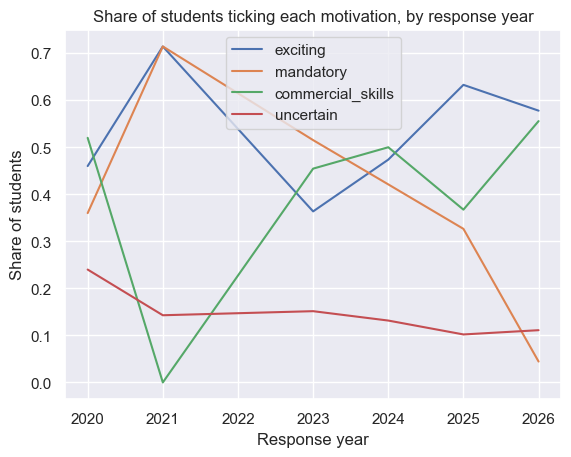

In [4]:
# Share of students ticking each motivation, per response year
motivations = ["exciting", "mandatory", "commercial_skills", "uncertain"]

shares_by_year = df.groupby("response_year")[motivations].mean()

# One line per motivation, with the response year on the x-axis
ax = shares_by_year.plot()

# Title and axis labels
ax.set_title("Share of students ticking each motivation, by response year")
ax.set_xlabel("Response year")
ax.set_ylabel("Share of students")

## 2. Distribution (histogram and density plot)

**Question:** what does the distribution of `height_cm` look like? Is it bell-shaped, skewed, or does it have more than one peak? What might explain the shape?

**Background**

- A **distribution** describes how the values of one variable are spread: which values occur, and how often.
- A **histogram** splits the range of values into **bins** and counts how many students fall in each bin. The height of a bar is that count. The number of bins changes how the plot looks, not the data: too few bins hide the shape, too many look noisy.
- A **density plot** (KDE) draws a smooth curve through the same data, so it does not depend on bin edges. `kde=True` in `sns.histplot` draws the curve on top of the histogram, and `sns.kdeplot` draws only the curve. The setting `bw_adjust` controls how smooth the curve is.
- The **shape** can be symmetric, left-skewed (longer tail to the left, mean below median), right-skewed (longer tail to the right, mean above median), or bimodal (two peaks, which can mean two groups).
- Useful numbers to read next to the plot: mean, median and standard deviation.

Text(0, 0.5, 'Number of students')

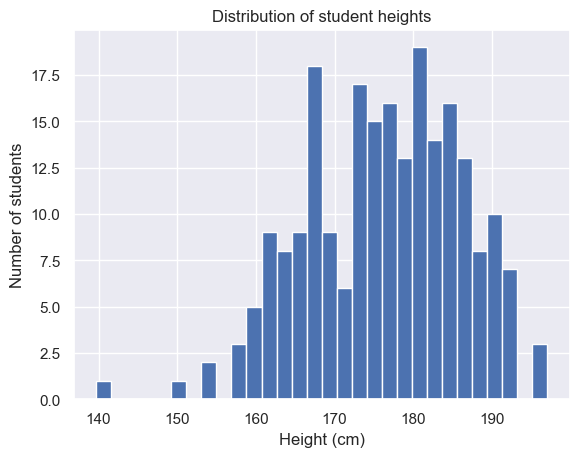

In [29]:
fig, ax = plt.subplots()          # create the figure and keep the axes in `ax`
ax.hist(df["height_cm"], bins=30) # draw on this specific axes
ax.set_title("Distribution of student heights")
ax.set_xlabel("Height (cm)")
ax.set_ylabel("Number of students")

Text(0, 0.5, 'Number of students')

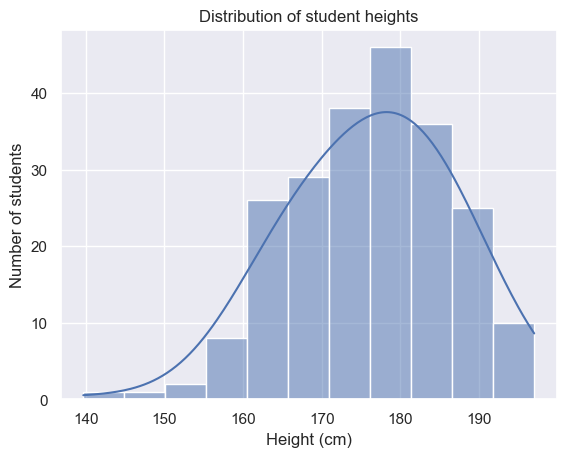

In [6]:
sns.histplot(df["height_cm"], kde=True, kde_kws={"bw_adjust": 2}) # Density curve
plt.title("Distribution of student heights")
plt.xlabel("Height (cm)")
plt.ylabel("Number of students")

**What we see:**

- One main hump centred around 176–180 cm, with a slightly longer tail on the left (shorter students).
- The mean (about 176.3) is a little below the median (about 177.8), which fits a slightly left-skewed distribution.
- The shape could be two overlapping groups with different average heights, but the data has no gender column, so we cannot confirm that.
- The number of bins changes how the histogram looks, not the data. The density curve smooths the bars into one hump.

**Density plot on its own**

The curve above is drawn over the histogram. To see only the density curve, use `sns.kdeplot`. The y-axis is then *density* (the area under the curve is 1), not a count of students.

Text(0, 0.5, 'Density')

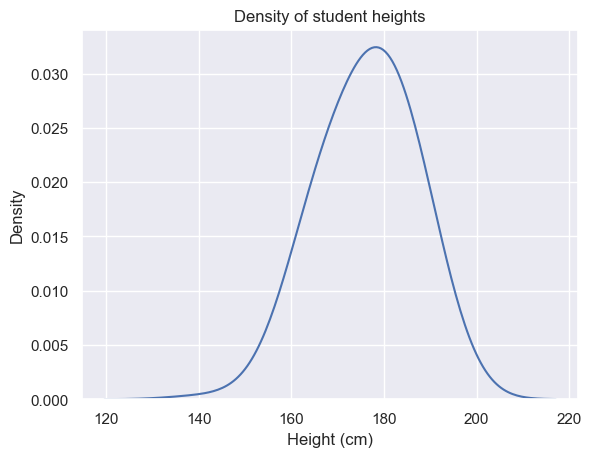

In [7]:
# Density plot of height_cm, without the histogram bars (bw_adjust=2 smooths more than the default)
sns.kdeplot(df["height_cm"], bw_adjust=2)

# Title and axis labels (the y-axis is density, not a count)
plt.title("Density of student heights")
plt.xlabel("Height (cm)")
plt.ylabel("Density")

## 3. Spread (standard deviation)

**Question:** what are the mean, median, standard deviation and variance of `height_cm`?
What share of students fall within 1, 2 and 3 standard deviations of the mean? Does that match what you would expect from a normal distribution (about 68%, 95% and 99.7%)?

np.float64(9.823618305971472)

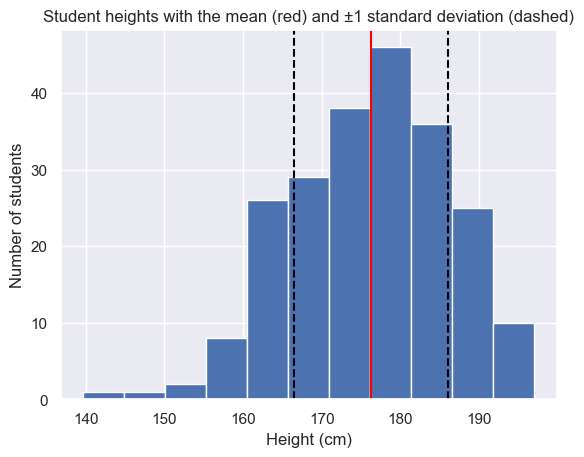

In [8]:
# Mean and sample standard deviation (n-1) of the heights
mean = df["height_cm"].mean()
std = df["height_cm"].std()

# Histogram of the heights
plt.hist(df["height_cm"], bins=11)

# Red line at the mean, dashed lines one standard deviation below and above it
plt.axvline(mean, color="red")
plt.axvline(mean - std, color="black", linestyle="--")
plt.axvline(mean + std, color="black", linestyle="--")

# Title and axis labels
plt.title("Student heights with the mean (red) and ±1 standard deviation (dashed)")
plt.xlabel("Height (cm)")
plt.ylabel("Number of students")

# Show the standard deviation as a number
display(std)

**What we see:**

- The red line is the mean height, about 176.3 cm.
- The dashed lines are one standard deviation (about 9.8 cm) below and above the mean, at about 166.5 and 186.1 cm.
- About two thirds of the students (67%) fall between the dashed lines, close to the 68% expected from a normal distribution.
- The few students further out, especially on the left, form the tail.

Text(0, 0.5, 'Number of students')

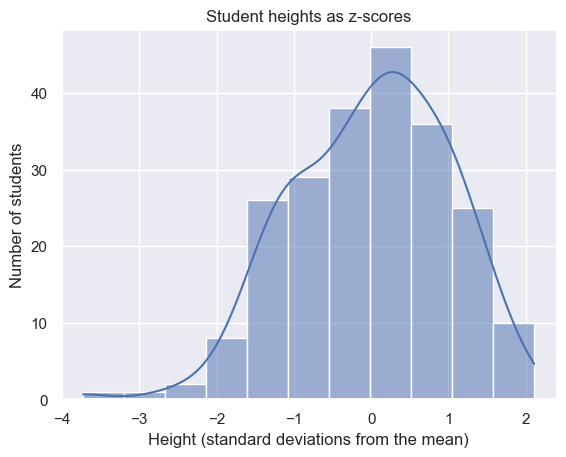

In [9]:
# z-score: how many standard deviations each height is from the mean
z = (df["height_cm"] - mean) / std

# Histogram with a density curve of the z-scores
sns.histplot(z, kde=True)

# Title and axis labels (the x-axis is now in standard deviations, not cm)
plt.title("Student heights as z-scores")
plt.xlabel("Height (standard deviations from the mean)")
plt.ylabel("Number of students")

**What we see:**

- The same data in standard units (z-scores): 0 is the mean height, and 1 is one standard deviation above it.
- The shape is unchanged, only the x-axis is different.
- The leftmost value is about −3.7, which is the shortest student (about 140 cm). That is far outside ±3, so it is an unusual value.
- The right side only reaches about 2.1, which is the longer left tail (the left skew).

## 4. Comparing groups (box plot)

**Question:** how does `days_after_open` differ between the years in `source_file`? In which year do students answer the fastest, and which has the widest spread? Are there outliers?

Text(0, 0.5, 'Days after the survey opened')

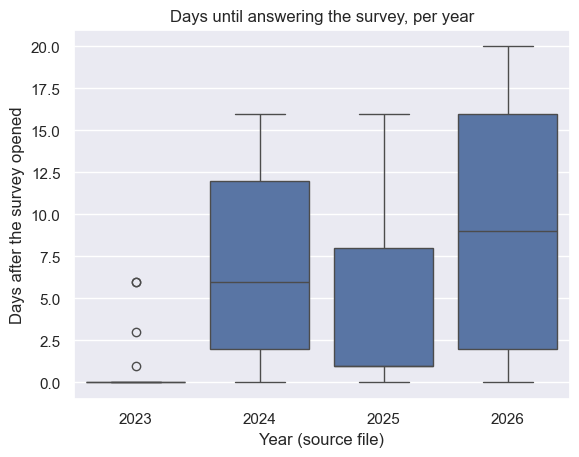

In [10]:
# One box per year: the line is the median, the box is the middle 50% of the students
sns.boxplot(x=df["source_file"], y=df["days_after_open"])

# Title and axis labels
plt.title("Days until answering the survey, per year")
plt.xlabel("Year (source file)")
plt.ylabel("Days after the survey opened")

**What we see:**

| Year | Median (days) | Box (middle 50%) | Box height |
|---|---|---|---|
| 2023 | 0 | 0 to 0 | 0 |
| 2024 | 6 | 2 to 12 | 10 |
| 2025 | 1 | 1 to 8 | 7 |
| 2026 | 9 | 2 to 16 | 14 |

- **Fastest:** 2023, where almost everyone answered on day 0. That file was collected in class, so the answers came in one burst, and it is not comparable with the other years. Among the years where students answered at their own pace, 2025 is the fastest (median 1 day).
- **Widest spread:** 2026. It has the tallest box (14 days) and the longest whiskers (up to 20 days), and it also has the latest median (9 days).
- **Outliers:** only 2023 shows dots (at 1, 3 and 6 days). They are outliers only because the rest of that year is squashed at 0, not because they are errors.
- **Reading a box:** a higher box means later answers, and a taller box means a wider spread.

## 5. Categories (bar chart and grouped bar chart)

**Question:** how many students are there per `programme_clean`? Then show programme per year with a grouped or stacked bar chart. Has the class become more homogeneous over the years?

### 5.1 Students per programme

One bar per programme, with the height showing the number of students. There are two common ways to get it, and both give the same chart.

- **pandas:** count with `value_counts()` and draw with `.plot(kind="bar")`.
- **seaborn:** `sns.countplot` counts and draws in one call.

Software Design dominates (178 of 222 students), and three programmes have only 1 or 2 students, so they are barely visible.

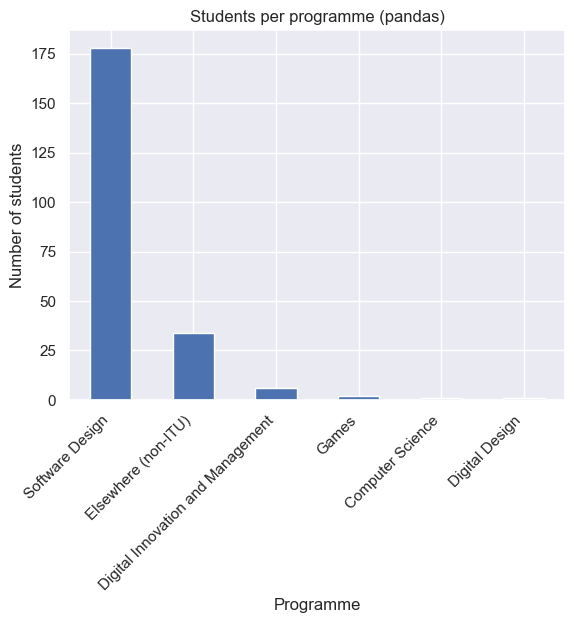

In [11]:
# pandas: count the students per programme, then draw the counts as bars
df["programme_clean"].value_counts().plot(kind="bar")

# Title and axis labels (rotate the long names so they do not overlap)
plt.title("Students per programme (pandas)")
plt.xlabel("Programme")
plt.ylabel("Number of students")
plt.xticks(rotation=45, ha="right");

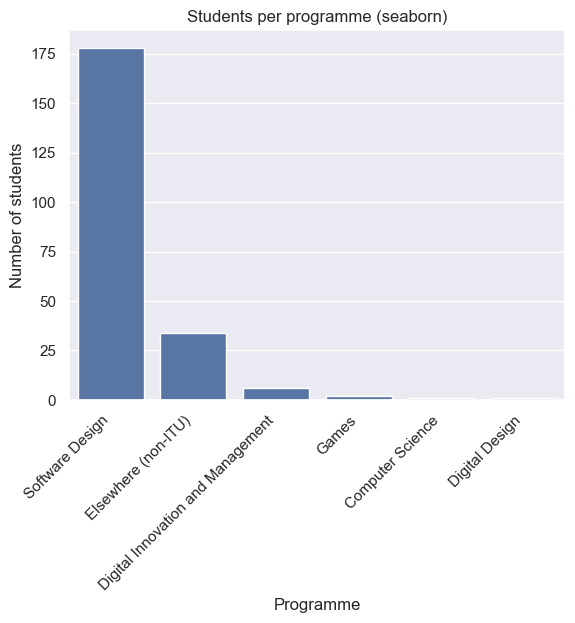

In [12]:
# seaborn: countplot counts the rows per category and draws the bars in one call
sns.countplot(x=df["programme_clean"], order=df["programme_clean"].value_counts().index)

# Title and axis labels
plt.title("Students per programme (seaborn)")
plt.xlabel("Programme")
plt.ylabel("Number of students")
plt.xticks(rotation=45, ha="right");

### 5.2 Programme per year: the table

Both charts below start from a table with one row per year and one column per programme. Two ways to build it:

- `pd.crosstab(...)`, made for counting combinations of two categories.
- `df.groupby([...]).size().unstack()`, which groups by both columns, counts, and turns the second column into table columns.

They give the same numbers.

In [13]:
# Way 1: crosstab (rows = year, columns = programme, cells = number of students)
table = pd.crosstab(df["source_file"], df["programme_clean"])
table

programme_clean,Computer Science,Digital Design,Digital Innovation and Management,Elsewhere (non-ITU),Games,Software Design
source_file,,,,,,
2023,1,0,0,19,1,69
2024,0,0,4,3,1,30
2025,0,1,2,12,0,34
2026,0,0,0,0,0,45


In [14]:
# Way 2: groupby + size + unstack gives the same table
df.groupby(["source_file", "programme_clean"]).size().unstack(fill_value=0)

programme_clean,Computer Science,Digital Design,Digital Innovation and Management,Elsewhere (non-ITU),Games,Software Design
source_file,,,,,,
2023,1,0,0,19,1,69
2024,0,0,4,3,1,30
2025,0,1,2,12,0,34
2026,0,0,0,0,0,45


### 5.3 Grouped bar chart (counts)

For each year, one bar per programme, side by side. Good for comparing the *numbers*, but the years have different sizes (90, 38, 49 and 45 students), so it is hard to compare the *mix*.

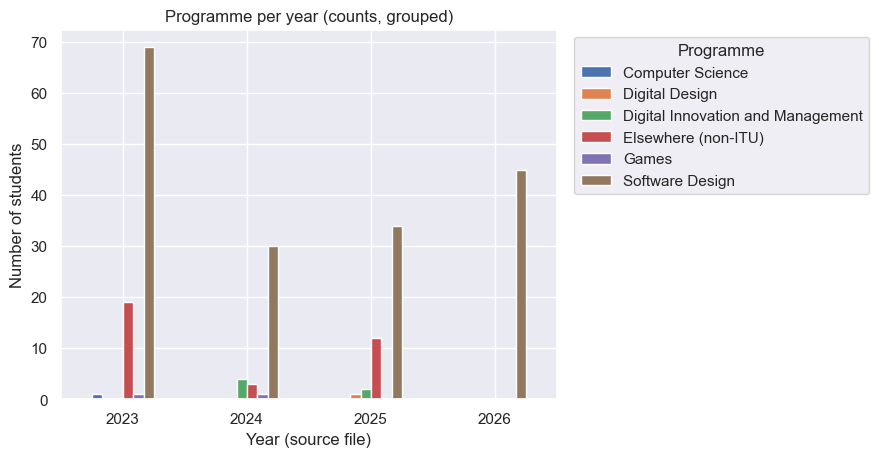

In [15]:
# Grouped bars: one group per year, one bar per programme
table.plot(kind="bar")

# Title, axis labels and a legend placed outside the plot
plt.title("Programme per year (counts, grouped)")
plt.xlabel("Year (source file)")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.legend(title="Programme", bbox_to_anchor=(1.02, 1), loc="upper left");

**Another way:** seaborn's `countplot` with `hue` makes the same grouped chart directly from the DataFrame, without building the table first.

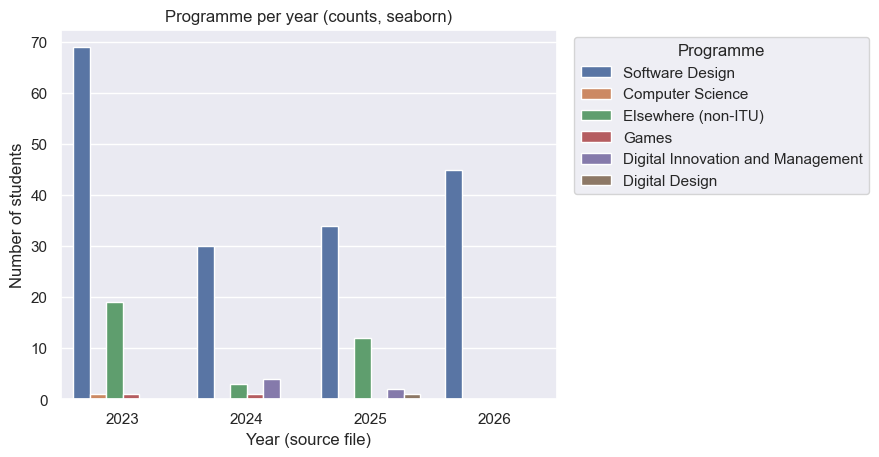

In [16]:
# Seaborn: x = year, hue = programme, counted for you
sns.countplot(data=df, x="source_file", hue="programme_clean")

# Title and axis labels
plt.title("Programme per year (counts, seaborn)")
plt.xlabel("Year (source file)")
plt.ylabel("Number of students")
plt.legend(title="Programme", bbox_to_anchor=(1.02, 1), loc="upper left");

### 5.4 Stacked bar chart (counts)

The programmes are stacked into one bar per year, so the bar height is the total number of students that year. It is easier to compare the totals, but the small segments are hard to compare between years.

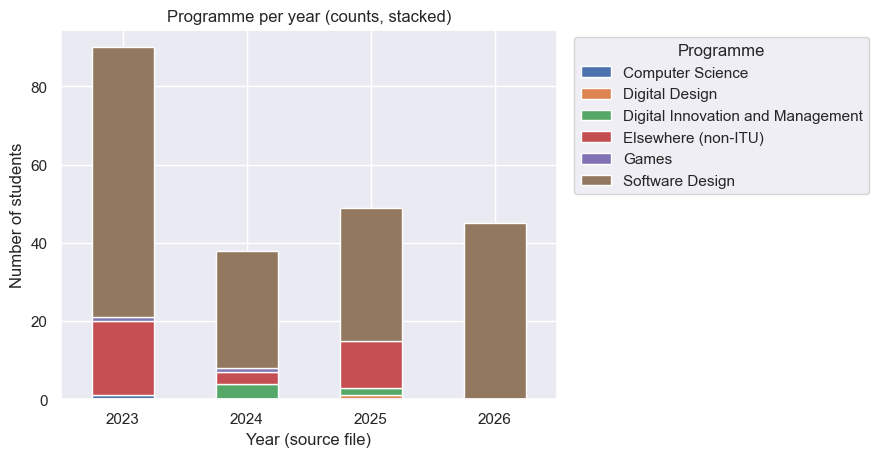

In [17]:
# Same table, with stacked=True
table.plot(kind="bar", stacked=True)

# Title, axis labels and legend
plt.title("Programme per year (counts, stacked)")
plt.xlabel("Year (source file)")
plt.ylabel("Number of students")
plt.xticks(rotation=0)
plt.legend(title="Programme", bbox_to_anchor=(1.02, 1), loc="upper left");

### 5.5 Stacked bar chart (shares)

This one answers the homogeneity question, because it compares the **mix** and not the sizes. `normalize="index"` goes into `pd.crosstab`, which calculates the shares per row. `.plot` only draws what it is given.

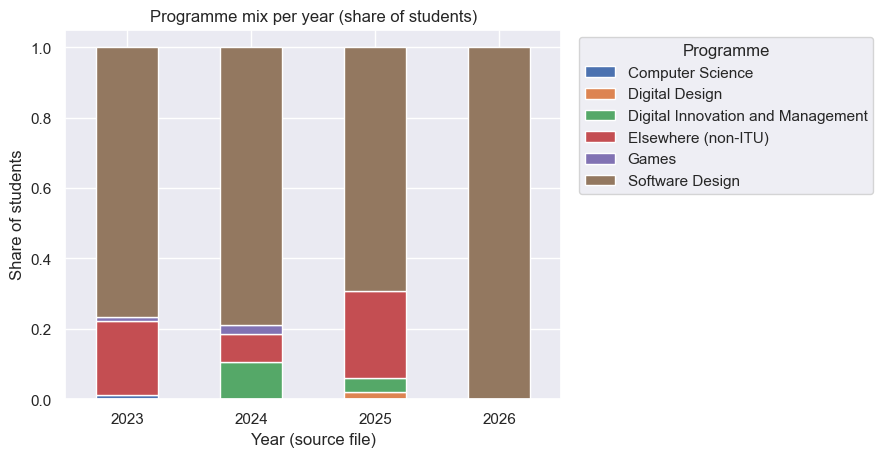

In [18]:
# Step 1: shares per year (each row sums to 1). normalize belongs to crosstab
shares = pd.crosstab(df["source_file"], df["programme_clean"], normalize="index")

# Step 2: draw the shares as stacked bars (every bar reaches 1.0)
shares.plot(kind="bar", stacked=True)

# Title, axis labels and legend
plt.title("Programme mix per year (share of students)")
plt.xlabel("Year (source file)")
plt.ylabel("Share of students")
plt.xticks(rotation=0)
plt.legend(title="Programme", bbox_to_anchor=(1.02, 1), loc="upper left");

**What we see:**

| Year | Software Design | Others |
|---|---|---|
| 2023 | 77% | 23% |
| 2024 | 79% | 21% |
| 2025 | 69% | 31% |
| 2026 | 100% | 0% |

- Software Design is by far the largest programme in every year (178 of 222 students), and the "Elsewhere (non-ITU)" group is the second largest (34).
- The class did not become more homogeneous gradually. 2023 to 2025 stay at roughly 70-80% Software Design, with 2025 the most mixed, and then 2026 is a jump to 100%.
- The programmes with 1 or 2 students (Games, Computer Science, Digital Design) are too small to say anything about.
- The change in 2026 happens at the same time as the course became free choice and "mandatory" almost disappeared, so the two changes are hard to separate: a different mix of students could explain part of the drop.
- **Which chart for what:** counts (grouped or stacked) show how many, and shares show the mix. For the question "has the class become more homogeneous", the shares chart is the right one.

## 6. Relationships (scatter plot with trend line, and correlation heatmap)

**Question:** is there a relationship between `height_cm` and `shoe_eu`? Add a trend line. Then make a correlation heatmap of the numeric columns (height, shoe size, `days_after_open` and the four 0/1 flags). Which pairs are strongest, positive and negative, and do they make sense?

### 6.1 Basic scatter plot

Each dot is one student: shoe size on the x-axis, height on the y-axis.

- The dots slope upwards, so bigger shoe sizes go with taller students (correlation about 0.80).
- One dot sits far from the rest: shoe size 42 and about 140 cm, the shortest student.
- **Problem (overplotting):** shoe sizes are whole or half numbers and heights are often rounded, so many students share exactly the same coordinates and hide each other. Only 159 distinct dots are visible for 222 students.

Text(0, 0.5, 'Height (cm)')

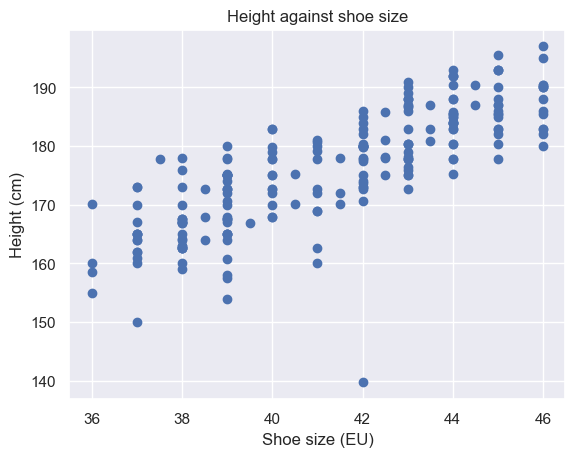

In [19]:
# x is the shoe size, y is the height
x_values = df["shoe_eu"]
y_values = df["height_cm"]

# One dot per student
plt.scatter(x_values, y_values)

# Title and axis labels
plt.title("Height against shoe size")
plt.xlabel("Shoe size (EU)")
plt.ylabel("Height (cm)")

### 6.2 Fix 1: transparency

`alpha=0.3` makes each dot see-through, so where several students overlap the dot looks darker.

- It is the quickest fix, and it needs no extra calculation.
- A darker dot means more students, but the darkness is hard to read as an exact number.

Text(0, 0.5, 'Height (cm)')

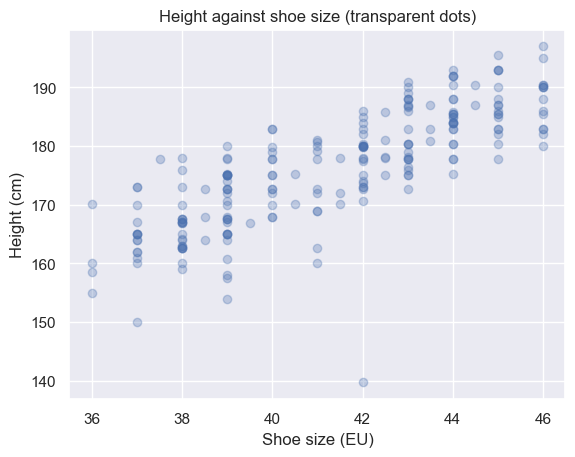

In [20]:
# Same scatter plot, but with see-through dots so overlaps look darker
plt.scatter(x_values, y_values, alpha=0.3)

# Title and axis labels
plt.title("Height against shoe size (transparent dots)")
plt.xlabel("Shoe size (EU)")
plt.ylabel("Height (cm)")

### 6.3 Fix 2: dot size = number of students

First count the students for every (shoe size, height) pair, then draw one dot per distinct pair with its size proportional to that count.

- The biggest dot is 6 students (shoe size 39 and 175 cm).
- The big dots sit near the middle of each column, along the trend, and the isolated small dots at the edges are the less typical students.

Text(0, 0.5, 'Height (cm)')

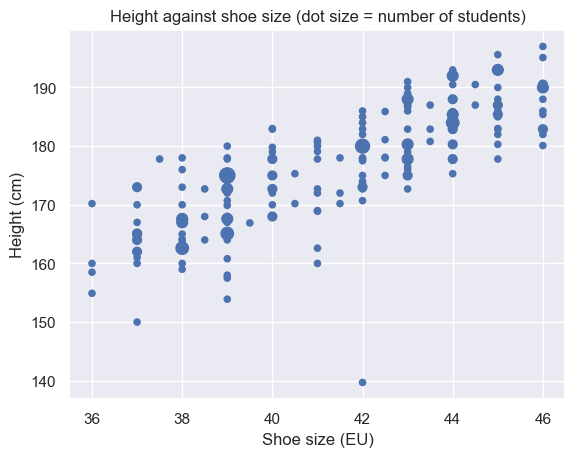

In [21]:
# Count how many students share each (shoe size, height) pair
points = df.groupby(["shoe_eu", "height_cm"]).size().reset_index(name="count")

# One dot per distinct pair, with the size growing with the count
plt.scatter(points["shoe_eu"], points["height_cm"], s=points["count"] * 20)

# Title and axis labels (the title says what the dot size means)
plt.title("Height against shoe size (dot size = number of students)")
plt.xlabel("Shoe size (EU)")
plt.ylabel("Height (cm)")

### 6.4 Fix 3: jitter

Jitter nudges every dot by a small random amount, so students with identical values spread out slightly instead of stacking.

- The nudge is only for drawing. The data itself is not changed.
- Use small amounts, otherwise the plot starts to show values that do not exist.

Text(0, 0.5, 'Height (cm)')

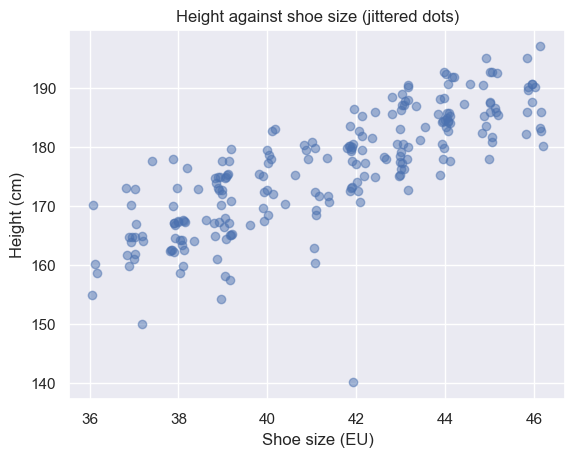

In [22]:
# Scatter plot with a small random nudge in x and y (no trend line yet)
sns.regplot(x=x_values, y=y_values, fit_reg=False,
            x_jitter=0.2, y_jitter=0.5, scatter_kws={"alpha": 0.5})

# Title and axis labels
plt.title("Height against shoe size (jittered dots)")
plt.xlabel("Shoe size (EU)")
plt.ylabel("Height (cm)")

### 6.5 Fix 4: hexbin

The slides name hexbin as the standard answer for two numeric variables with many points. The plane is divided into small hexagons, and each hexagon is coloured by how many students fall inside it.

- The colour scale shows the count, so crowded areas are easy to see.
- Individual students are no longer visible, so this suits larger datasets better. With 222 students it is a coarse picture.
- `gridsize` sets how many hexagons fit across the plot: more gives finer detail but noisier colours.

Text(0, 0.5, 'Height (cm)')

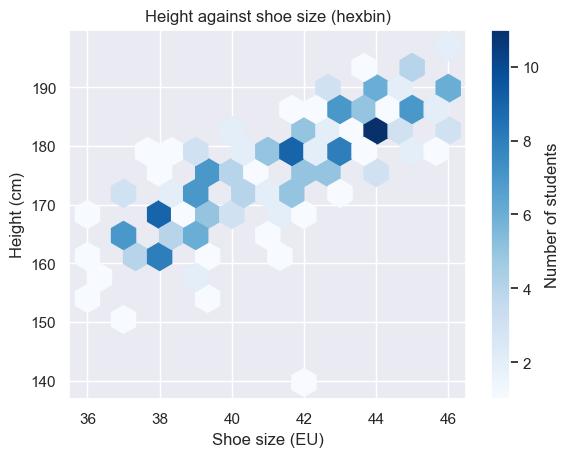

In [23]:
# Colour each hexagon by the number of students in it (empty hexagons are hidden)
plt.hexbin(x_values, y_values, gridsize=15, mincnt=1, cmap="Blues")

# A colour bar that says what the colours mean
plt.colorbar(label="Number of students")

# Title and axis labels
plt.title("Height against shoe size (hexbin)")
plt.xlabel("Shoe size (EU)")
plt.ylabel("Height (cm)")

### 6.6 Trend line

`sns.regplot` draws the dots and a fitted straight line (a linear regression), with a shaded band that shows the uncertainty of the line.

- The line is roughly height = 2.8 × shoe size + 60, so each extra shoe size is about 2.8 cm taller.
- The typical distance of a student from the line is about 6 cm, smaller than the spread of all heights (9.8 cm).
- The far-away student (42 / 140 cm) pulls the line down slightly.

Text(0, 0.5, 'Height (cm)')

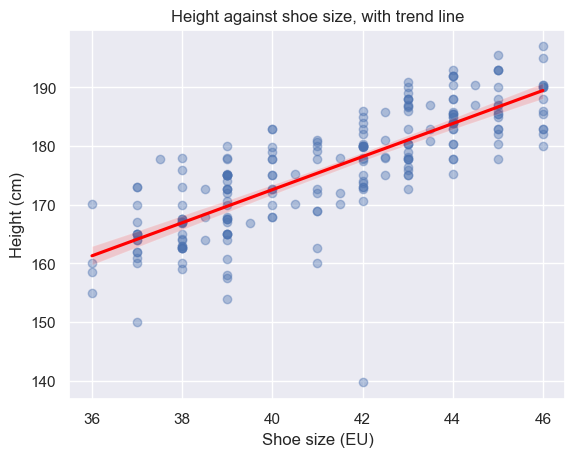

In [24]:
# Dots (transparent) plus the fitted straight line in red
sns.regplot(x=x_values, y=y_values,
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})

# Title and axis labels
plt.title("Height against shoe size, with trend line")
plt.xlabel("Shoe size (EU)")
plt.ylabel("Height (cm)")

### 6.7 Correlation heatmap

A correlation matrix gives one number between −1 and +1 for every pair of numeric columns, and the heatmap colours that table so strong pairs stand out. Here it covers height, shoe size, `days_after_open` and the four 0/1 motivation flags.

<Axes: >

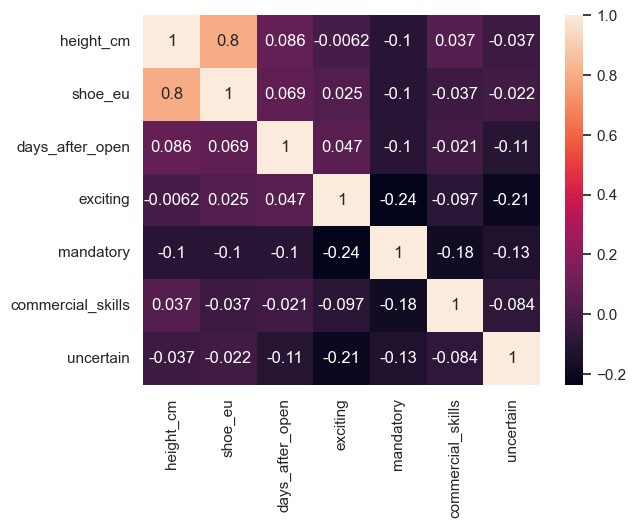

In [25]:
cols = ["height_cm", "shoe_eu", "days_after_open",
        "exciting", "mandatory", "commercial_skills", "uncertain"]

corr = df[cols].corr()
corr

sns.heatmap(corr, annot=True)

**What we see:**

- **Strongest pair:** `height_cm` and `shoe_eu`, about +0.80. It is the only strong correlation, and it makes sense: taller students tend to have bigger feet.
- **Weak negative pairs between the motivations:** `exciting` and `mandatory` (−0.24), `exciting` and `uncertain` (−0.21), `mandatory` and `commercial_skills` (−0.18). They come from the same multiple-choice question, so ticking one reason makes ticking another a little less likely.
- **Timing and motivation:** `days_after_open` against the four motivations lies between −0.11 and +0.05. With 222 students, values below about ±0.13 cannot be told apart from chance, so there is no detectable linear relationship between when a student answered and why they took the course.
- **Height and shoe size against the motivations:** all close to 0 (between −0.10 and +0.04).
- **Limits:** Pearson correlation only measures straight-line relationships, the data pools all years including the in-class 2023 file, and correlation is not causation.

## 7. Interactive and automatic (Plotly and ydata_profiling)

**Question:** make an interactive scatter of `height_cm` against `shoe_eu`, coloured by `programme_clean`, with the motivation shown when you hover. Then generate the `ydata_profiling` report. What does the report show that you had not noticed?